# Module 02 — Matrices and Linear Maps

This notebook is the runnable companion to the concept guide. It shows a matrix acting as a
*function* on vectors, composes such functions with `@`, draws what rotations, shears and
projections do to the unit square, detects rank deficiency in a feature matrix, solves linear
systems the right way (and watches the wrong way fail on an ill-conditioned matrix), fits least
squares three different ways, diagonalises a map by changing basis, and runs a Markov chain to
its stationary distribution.

Read the [concept guide](README.md) first, or keep it open alongside: each section below mirrors
a numbered section there.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)
np.set_printoptions(precision=4, suppress=True)

## 1. Four ways to read $A\mathbf{x}$

The product of an $m \times n$ matrix with a vector in $\mathbb{R}^n$ is defined entry by entry,
$(A\mathbf{x})_i = \sum_j A_{ij} x_j$, but you should be able to *see* it in four ways:

* **row picture** — entry $i$ is the dot product of row $i$ with $\mathbf{x}$;
* **column picture** — $A\mathbf{x} = x_1 \mathbf{a}_1 + \dots + x_n \mathbf{a}_n$, a linear combination of the columns;
* **function** — $\mathbf{x} \mapsto A\mathbf{x}$ is a linear map $\mathbb{R}^n \to \mathbb{R}^m$, fully determined by where it sends the basis vectors (the columns);
* **system of equations** — $A\mathbf{x} = \mathbf{b}$ is $m$ equations in $n$ unknowns.

The cell below computes all three numeric versions for $A = \begin{pmatrix}1&2\\3&4\end{pmatrix}$,
$\mathbf{x} = (2, -1)^\top$, then applies the row picture to a small patient data matrix.

In [2]:
A = np.array([[1., 2.],
              [3., 4.]])
x = np.array([2., -1.])

row_picture = np.array([A[i] @ x for i in range(A.shape[0])])          # dot product per row
col_picture = sum(x[j] * A[:, j] for j in range(A.shape[1]))           # weighted sum of columns
print("row picture   :", row_picture)
print("column picture:", col_picture)
print("A @ x         :", A @ x)
print("images of the basis vectors e1, e2 are the columns:", A @ np.array([1., 0.]), A @ np.array([0., 1.]))

# A data matrix X (n patients x d features) times a weight vector = one score per patient
X = np.array([[6., 14., 30.],     # age (decades), systolic BP (x10 mmHg), BMI
              [4., 12., 22.],
              [7., 16., 28.],
              [5., 13., 35.]])
w = np.array([0.3, 0.5, 0.2])
scores = X @ w
print("\nrisk scores (row picture, one dot product per patient):", scores)
print("same scores as a combination of feature columns   :", 0.3 * X[:, 0] + 0.5 * X[:, 1] + 0.2 * X[:, 2])

row picture   : [0. 2.]
column picture: [0. 2.]
A @ x         : [0. 2.]
images of the basis vectors e1, e2 are the columns: [1. 3.] [2. 4.]

risk scores (row picture, one dot product per patient): [14.8 11.6 15.7 15. ]
same scores as a combination of feature columns   : [14.8 11.6 15.7 15. ]


Notice that the three computations agree to the last digit — they are the same sum, grouped
differently. The *column* grouping is the one to remember for the rest of this module: every
score vector `X @ w` you can ever produce is a combination of the three feature columns, so it
lives in a 3-dimensional subspace of $\mathbb{R}^4$. If the true risks do not lie in that
subspace (they never exactly do), no weight vector reproduces them and the best you can do is
the *closest* point in the subspace — that is least squares, Section 7.

## 2. Matrix multiplication as composition

$(AB)_{ij} = \sum_k A_{ik} B_{kj}$ is the dot product of row $i$ of $A$ with column $j$ of $B$,
and $(AB)\mathbf{x} = A(B\mathbf{x})$: apply $B$, then $A$. Three consequences you can test:

1. the product is **not commutative** ($AB \ne BA$ in general);
2. the cost of a square $n \times n$ product grows like $n^3$ — doubling $n$ costs about $8\times$;
3. two linear layers in a row collapse into one matrix: $W_2(W_1\mathbf{x}) = (W_2 W_1)\mathbf{x}$.

We first write the triple loop ourselves, then check it against NumPy's `@`.

In [3]:
def matmul_loops(A, B):
    m, p = A.shape
    p2, n = B.shape
    assert p == p2, "inner dimensions must match"
    C = np.zeros((m, n))
    for i in range(m):
        for j in range(n):
            for k in range(p):
                C[i, j] += A[i, k] * B[k, j]
    return C

A = np.array([[1., 2.], [3., 4.]])
B = np.array([[0., 1.], [1., 0.]])          # a permutation (swap) matrix
print("A @ B =\n", A @ B, "\nB @ A =\n", B @ A)
print("loops agree with @ :", np.allclose(matmul_loops(A, B), A @ B))

# cubic cost: time the loop version for n, 2n, 4n
for n in (30, 60, 120):
    M = rng.standard_normal((n, n))
    t0 = time.perf_counter(); matmul_loops(M, M); dt = time.perf_counter() - t0
    print(f"n = {n:4d}: {n**3:>10,d} multiply-adds, loops took {dt*1000:7.1f} ms")

# a two-layer *linear* network is one matrix
W1 = rng.standard_normal((5, 3))      # 3 inputs -> 5 hidden
W2 = rng.standard_normal((2, 5))      # 5 hidden -> 2 outputs
x = rng.standard_normal(3)
print("\nW2 @ (W1 @ x) =", W2 @ (W1 @ x))
print("(W2 @ W1) @ x =", (W2 @ W1) @ x, "   combined shape:", (W2 @ W1).shape)

# batching: one call multiplies a whole stack of matrices
batch = rng.standard_normal((8, 4, 3))    # 8 matrices of shape 4x3
print("batch @ W  ->", (batch @ rng.standard_normal((3, 2))).shape)

A @ B =
 [[2. 1.]
 [4. 3.]] 
B @ A =
 [[3. 4.]
 [1. 2.]]
loops agree with @ : True
n =   30:     27,000 multiply-adds, loops took     8.0 ms
n =   60:    216,000 multiply-adds, loops took    69.7 ms


n =  120:  1,728,000 multiply-adds, loops took   716.3 ms

W2 @ (W1 @ x) = [ 4.8734 -0.6042]
(W2 @ W1) @ x = [ 4.8734 -0.6042]    combined shape: (2, 3)
batch @ W  -> (8, 4, 2)


Notice that $AB$ swaps the *columns* of $A$ while $BA$ swaps its *rows* — the same permutation
matrix does different things depending on which side it sits. The timings roughly multiply by 8
each time $n$ doubles, the signature of $n^3$ (NumPy's `@` does the same count of operations in
optimised, parallel BLAS code, which is why the same product on a GPU is thousands of times
faster). And `W2 @ W1` reproduces the two-step computation exactly: without a nonlinearity between
them, two layers are one layer with fewer degrees of freedom than their parameter count suggests.

**Try it yourself:** change the batch shape to `(8, 4, 3)` and multiply by `W1.T` (shape `(3, 5)`) —
predict the output shape before you run it. Then try `A * B` instead of `A @ B` and compare.

## 3. Geometry: what a $2\times2$ matrix does to the unit square

Apply a matrix to the corners of the unit square and you get a parallelogram whose edges are
the two columns. Its signed area is the determinant $\det\begin{pmatrix}a&b\\c&d\end{pmatrix} = ad - bc$:
$|\det|$ is the area-scaling factor, a negative sign means the orientation flipped, and
$\det = 0$ means the square was squashed onto a line — a dimension was lost.

$$
R_\theta = \begin{pmatrix}\cos\theta & -\sin\theta\\ \sin\theta & \cos\theta\end{pmatrix},\quad
S = \begin{pmatrix}s_x & 0\\ 0 & s_y\end{pmatrix},\quad
H_k = \begin{pmatrix}1 & k\\ 0 & 1\end{pmatrix},\quad
F = \begin{pmatrix}1 & 0\\ 0 & -1\end{pmatrix},\quad
P_{\mathbf u} = \mathbf{u}\mathbf{u}^\top .
$$

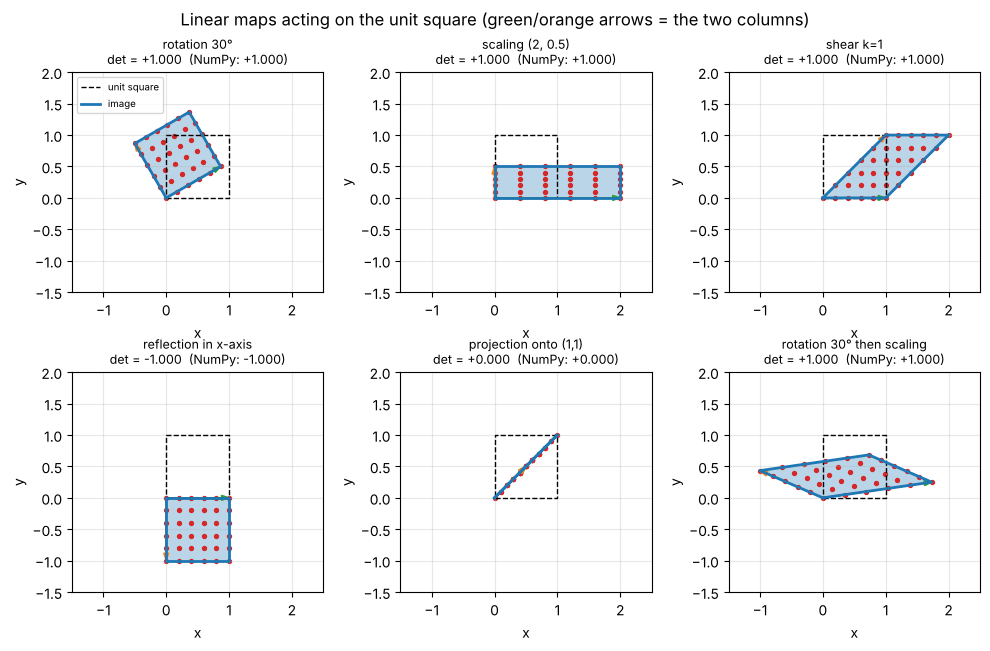

det(S @ R) = det(S) * det(R): 1.0 = 1.0


In [4]:
def rotation(theta):
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, -s], [s, c]])

def scaling(sx, sy):
    return np.array([[sx, 0.], [0., sy]])

def shear(k):
    return np.array([[1., k], [0., 1.]])

def reflection_x():
    return np.array([[1., 0.], [0., -1.]])

def projection(u):
    u = np.asarray(u, dtype=float); u = u / np.linalg.norm(u)
    return np.outer(u, u)

def det2(M):
    return M[0, 0] * M[1, 1] - M[0, 1] * M[1, 0]

square = np.array([[0, 1, 1, 0, 0],      # x coordinates of the corners (closed polygon)
                   [0, 0, 1, 1, 0.]])    # y coordinates
grid = np.array([[gx, gy] for gx in np.linspace(0, 1, 6) for gy in np.linspace(0, 1, 6)]).T

maps = {"rotation 30°": rotation(np.pi / 6), "scaling (2, 0.5)": scaling(2, 0.5),
        "shear k=1": shear(1.0), "reflection in x-axis": reflection_x(),
        "projection onto (1,1)": projection([1, 1]), "rotation 30° then scaling": scaling(2, 0.5) @ rotation(np.pi / 6)}

fig, axes = plt.subplots(2, 3, figsize=(10, 6.5))
for ax, (name, M) in zip(axes.ravel(), maps.items()):
    img, g_img = M @ square, M @ grid
    ax.plot(square[0], square[1], "k--", lw=1, label="unit square")
    ax.fill(img[0], img[1], alpha=0.3, color="tab:blue")
    ax.plot(img[0], img[1], color="tab:blue", lw=2, label="image")
    ax.scatter(g_img[0], g_img[1], s=8, color="tab:red")
    ax.arrow(0, 0, *M[:, 0], head_width=0.08, color="tab:green", length_includes_head=True)
    ax.arrow(0, 0, *M[:, 1], head_width=0.08, color="tab:orange", length_includes_head=True)
    ax.set_title(f"{name}\ndet = {det2(M):+.3f}  (NumPy: {np.linalg.det(M):+.3f})", fontsize=9)
    ax.set_xlim(-1.5, 2.5); ax.set_ylim(-1.5, 2); ax.set_aspect("equal")
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=7, loc="upper left")
plt.suptitle("Linear maps acting on the unit square (green/orange arrows = the two columns)")
plt.tight_layout(); plt.show()

print("det(S @ R) = det(S) * det(R):", det2(scaling(2, 0.5) @ rotation(np.pi / 6)), "=", det2(scaling(2, 0.5)) * det2(rotation(np.pi / 6)))

Notice that the rotation and the shear both have determinant $+1$ — the slanted parallelogram has
exactly the same area as the square. The reflection has determinant $-1$: same area, but the
corners now run clockwise. The projection has determinant $0$ and the red grid points, which
were spread over the square, now all lie on one line: pairs of different inputs have become the
same output, and no matrix can undo that. Composition multiplies determinants.

## 4. Special matrices and what they promise

* **Orthogonal** $Q$: $Q^\top Q = I$, so $Q^{-1} = Q^\top$ and $\lVert Q\mathbf{x}\rVert = \lVert\mathbf{x}\rVert$ — lengths and angles survive.
* **Symmetric PSD**: $A = A^\top$ and $\mathbf{x}^\top A\mathbf{x} \ge 0$; every $A^\top A$ is one, because $\mathbf{x}^\top A^\top A\mathbf{x} = \lVert A\mathbf{x}\rVert^2$.
* **Triangular**: solve by back-substitution in $O(n^2)$ instead of $O(n^3)$.
* **Transpose rule**: $(AB)^\top = B^\top A^\top$ — the order flips.

In [5]:
Q = rotation(np.pi / 4)                                   # rotations are orthogonal
v = rng.standard_normal(2)
print("Q^T Q =\n", Q.T @ Q)
print("||v|| = %.4f   ||Qv|| = %.4f" % (np.linalg.norm(v), np.linalg.norm(Q @ v)))

M = rng.standard_normal((5, 3))
G = M.T @ M                                               # Gram matrix: symmetric and PSD
print("\nG symmetric:", np.allclose(G, G.T), "   eigenvalues of G:", np.linalg.eigvalsh(G))
for _ in range(3):
    z = rng.standard_normal(3)
    print("  z^T G z = %.3f  (= ||Mz||^2 = %.3f)" % (z @ G @ z, np.sum((M @ z) ** 2)))

K = np.array([[1., 2.], [2., 1.]])                        # symmetric but NOT PSD
z = np.array([1., -1.])
print("\nz^T K z for K=[[1,2],[2,1]], z=(1,-1):", z @ K @ z, "  eigenvalues:", np.linalg.eigvalsh(K))

A, B = rng.standard_normal((3, 2)), rng.standard_normal((2, 4))
print("\n(AB)^T == B^T A^T :", np.allclose((A @ B).T, B.T @ A.T))

# back-substitution on an upper-triangular system
U = np.array([[2., 1., -1.], [0., 3., 2.], [0., 0., 4.]])
b = np.array([3., 11., 8.])
x = np.zeros(3)
for i in range(2, -1, -1):
    x[i] = (b[i] - U[i, i + 1:] @ x[i + 1:]) / U[i, i]
print("back-substitution x =", x, "  check U @ x =", U @ x)

Q^T Q =
 [[ 1. -0.]
 [-0.  1.]]
||v|| = 1.3088   ||Qv|| = 1.3088

G symmetric: True    eigenvalues of G: [ 1.7609  3.6848 17.5874]
  z^T G z = 6.155  (= ||Mz||^2 = 6.155)
  z^T G z = 17.999  (= ||Mz||^2 = 17.999)
  z^T G z = 2.589  (= ||Mz||^2 = 2.589)

z^T K z for K=[[1,2],[2,1]], z=(1,-1): -2.0   eigenvalues: [-1.  3.]

(AB)^T == B^T A^T : True
back-substitution x = [1.3333 2.3333 2.    ]   check U @ x = [ 3. 11.  8.]


Notice that $\mathbf{z}^\top G\mathbf{z}$ equals $\lVert M\mathbf{z}\rVert^2$ for every draw — that is the whole
proof that Gram matrices are positive semidefinite, and it is why covariance matrices (which are
Gram matrices of centred data) always have non-negative eigenvalues. The matrix `K` looks harmless
but gives a negative quadratic form, so it cannot be a covariance matrix. The back-substitution
loop solved a $3\times3$ system with only $3 + 2 + 1 = 6$ multiplications: the triangular structure
is what `np.linalg.solve` buys itself by first factoring $A = LU$.

**Try it yourself:** replace `rotation(np.pi/4)` with `shear(1.0)` and re-run. Is $Q^\top Q$ still the
identity? Which norms change?

## 5. Rank, column space and null space — collinear features

$\operatorname{rank} A$ is the number of independent columns; $\dim\mathcal{N}(A) = n - \operatorname{rank} A$
(rank–nullity). In a data matrix a rank deficiency means some feature is an exact linear
combination of others, so the regression coefficients are not identifiable. Below, a synthetic
feature matrix with 1,000 rows contains an exact duplicate (a unit conversion) and a one-hot
group that sums to the intercept — the *dummy-variable trap*.

In [6]:
n = 1000
age = rng.uniform(20, 80, n)
weight_kg = rng.normal(75, 12, n)
height_cm = rng.normal(172, 9, n)
weight_lb = 2.2046 * weight_kg                                   # exact duplicate information
device = rng.integers(0, 3, n)                                   # 0 = mobile, 1 = desktop, 2 = tablet
one_hot = np.eye(3)[device]                                      # three 0/1 columns
intercept = np.ones(n)

X_good = np.column_stack([intercept, age, weight_kg, height_cm, one_hot[:, 1:]])   # drop one level
X_bad = np.column_stack([intercept, age, weight_kg, height_cm, weight_lb, one_hot])  # both traps

for name, X in [("X_good", X_good), ("X_bad", X_bad)]:
    r = np.linalg.matrix_rank(X)
    print(f"{name}: shape {X.shape}, rank {r}, null-space dimension {X.shape[1] - r}")

# null space of X_bad from the SVD: right-singular vectors with (numerically) zero singular value
_, s, Vt = np.linalg.svd(X_bad, full_matrices=False)
print("\nsingular values of X_bad:", s)
null_basis = Vt[s < 1e-8 * s.max()]

def tidy_basis(N, tol=1e-9):
    # row-reduce a basis of the null space so that each vector spells out ONE dependency
    N = N.copy(); r = 0
    for c in range(N.shape[1]):
        if r == N.shape[0]:
            break
        piv = r + np.argmax(np.abs(N[r:, c]))
        if abs(N[piv, c]) < tol:
            continue
        N[[r, piv]] = N[[piv, r]]; N[r] /= N[r, c]
        for i in range(N.shape[0]):
            if i != r:
                N[i] -= N[i, c] * N[r]
        r += 1
    N[np.abs(N) < 1e-6] = 0.0
    return N

cols = ["intercept", "age", "weight_kg", "height_cm", "weight_lb", "mobile", "desktop", "tablet"]
for z in tidy_basis(null_basis):
    relation = " ".join(f"{v:+.4f}*{c}" for c, v in zip(cols, z) if v != 0)
    print("null vector:", relation, "= 0   -> ||X_bad z|| = %.1e" % np.linalg.norm(X_bad @ z))

X_good: shape (1000, 6), rank 6, null-space dimension 0
X_bad: shape (1000, 8), rank 6, null-space dimension 2

singular values of X_bad: [8086.0142  681.7715  541.7147   18.615    17.8286    1.7862    0.
    0.    ]
null vector: +1.0000*intercept -1.0000*mobile -1.0000*desktop -1.0000*tablet = 0   -> ||X_bad z|| = 5.6e-15
null vector: +1.0000*weight_kg -0.4536*weight_lb = 0   -> ||X_bad z|| = 1.2e-12


Notice that `X_bad` has 8 columns but rank 6: the null space is two-dimensional, and the two
null vectors spell out exactly which columns are redundant — one says
`weight_kg - 0.4536 * weight_lb = 0` (i.e. $1/2.2046 = 0.4536$), the other says
`intercept - mobile - desktop - tablet = 0`. Any multiple of these vectors can be
added to a coefficient vector without changing a single prediction, so the "effect of weight" or
"effect of being on mobile" is meaningless until one column from each group is dropped (or a ridge
penalty is added). `X_good` does that and has full column rank.

## 6. Solving $A\mathbf{x} = \mathbf{b}$: `solve`, not `inv`

For an invertible square $A$ the solution is $\mathbf{x} = A^{-1}\mathbf{b}$ *on paper*. In code,
`np.linalg.solve` factors $A = LU$ and does two triangular solves — about $\tfrac23 n^3$ flops versus
roughly $2n^3$ for the explicit inverse — and commits less rounding error. How much rounding error
you can afford is governed by the **condition number** $\kappa(A)$: relative perturbations of the
data can be amplified by up to $\kappa(A)$ in the solution.

We solve the juice-blending system from the guide, time `solve` against `inv`, and then push a
$2\times2$ matrix towards singularity to watch the error grow with $\kappa$.

blend (dl of each concentrate): [2. 3. 1.]   residual: 0.0


600x600: solve 7.6 ms   inv(A) @ b 22.8 ms   ratio 3.0x


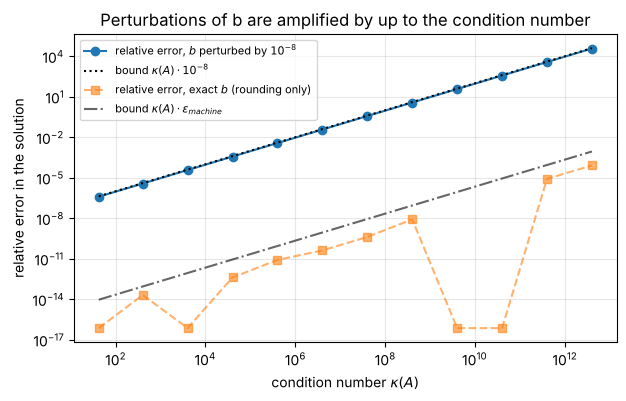

kappa * 1e-8 exceeds 1 (no correct digits left) once kappa > 1e8; here kappa reaches 4e+12
eps = 1e-4: kappa = 4.0e+04
b = (2, 2.0001) -> x = [1. 1.]
b = (2, 2.0002) -> x = [0. 2.]   (a 5e-5 relative change in b)


In [7]:
A = np.array([[1., 1., 2.],
              [2., 1., 1.],
              [1., 3., 1.]])
b = np.array([7., 8., 12.])
x = np.linalg.solve(A, b)
print("blend (dl of each concentrate):", x, "  residual:", np.linalg.norm(A @ x - b))

# cost: solve vs inverse on a 600x600 system
M = rng.standard_normal((600, 600)); rhs = rng.standard_normal(600)
t0 = time.perf_counter(); [np.linalg.solve(M, rhs) for _ in range(5)]; t_solve = (time.perf_counter() - t0) / 5
t0 = time.perf_counter(); [np.linalg.inv(M) @ rhs for _ in range(5)]; t_inv = (time.perf_counter() - t0) / 5
print(f"600x600: solve {t_solve*1000:.1f} ms   inv(A) @ b {t_inv*1000:.1f} ms   ratio {t_inv / t_solve:.1f}x")

# sensitivity: a family of increasingly ill-conditioned 2x2 matrices.
# We perturb b by a *relative* 1e-8 (think: measurement noise in the 8th digit) and watch
# how far the solution moves; the condition number predicts the amplification.
x_true = np.array([0.3, 0.7])
delta = 1e-8
eps_values = 10.0 ** -np.arange(1, 13)
kappas, err_pert, err_round = [], [], []
for eps in eps_values:
    A2 = np.array([[1., 1.], [1., 1. + eps]])
    b2 = A2 @ x_true
    b_noisy = b2 * (1 + delta * np.array([1., -1.]))          # relative perturbation of size delta
    kappas.append(np.linalg.cond(A2))
    err_pert.append(np.linalg.norm(np.linalg.solve(A2, b_noisy) - x_true) / np.linalg.norm(x_true))
    err_round.append(np.linalg.norm(np.linalg.solve(A2, b2) - x_true) / np.linalg.norm(x_true))
kappas = np.array(kappas)

plt.loglog(kappas, err_pert, "o-", label=r"relative error, $b$ perturbed by $10^{-8}$")
plt.loglog(kappas, kappas * delta, "k:", label=r"bound $\kappa(A)\cdot 10^{-8}$")
plt.loglog(kappas, np.maximum(err_round, 1e-17), "s--", alpha=0.6, label=r"relative error, exact $b$ (rounding only)")
plt.loglog(kappas, kappas * 2.2e-16, "k-.", alpha=0.6, label=r"bound $\kappa(A)\cdot\epsilon_{machine}$")
plt.xlabel(r"condition number $\kappa(A)$"); plt.ylabel("relative error in the solution")
plt.title("Perturbations of b are amplified by up to the condition number")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()
print("kappa * 1e-8 exceeds 1 (no correct digits left) once kappa > 1e8; here kappa reaches %.0e" % kappas[-1])

print("eps = 1e-4: kappa = %.1e" % kappas[3])
A4 = np.array([[1., 1.], [1., 1.0001]])
print("b = (2, 2.0001) -> x =", np.linalg.solve(A4, [2., 2.0001]))
print("b = (2, 2.0002) -> x =", np.linalg.solve(A4, [2., 2.0002]), "  (a 5e-5 relative change in b)")

Notice how the circles hug the dotted line $\kappa(A)\cdot 10^{-8}$: a perturbation in the eighth
digit of $\mathbf{b}$ is amplified by almost exactly the condition number, and once
$\kappa > 10^{8}$ the relative error in $\mathbf{x}$ exceeds 1 — not a single digit of the answer is
reliable. The rounding-only curve (exact $\mathbf{b}$) sits far lower but follows the same slope with
$\epsilon_{\text{machine}} \approx 2\times10^{-16}$ in place of $10^{-8}$: with $\kappa = 10^{10}$ you keep about
six digits, with $10^{16}$ none. Conditioning is a property of the *problem*, not the algorithm; `inv`
cannot fix it and costs roughly three times as much. The last two lines are the guide's example: a
change in the fifth decimal of $\mathbf{b}$ moves the solution from $(1, 1)$ to $(0, 2)$, because the
two columns of $A$ are almost parallel.

**Try it yourself:** change `delta` to `1e-4` (noise in the fourth digit) and read off the largest
$\kappa$ for which the solution still has two correct digits. Then try `np.linalg.solve` on
`X_bad.T @ X_bad` from Section 5 and read the error message.

## 7. Least squares three ways

With more observations than parameters, $A\mathbf{x} = \mathbf{y}$ has no exact solution. The
least-squares solution minimises $\lVert A\mathbf{x} - \mathbf{y}\rVert^2$; the residual must be orthogonal to
every column, $A^\top(\mathbf{y} - A\hat{\mathbf{x}}) = \mathbf{0}$, giving the **normal equations**

$$
A^\top A\,\hat{\mathbf{x}} = A^\top\mathbf{y}, \qquad \hat{\mathbf{y}} = H\mathbf{y}, \quad H = A(A^\top A)^{-1}A^\top .
$$

We fit a line to noisy data by (a) the normal equations from scratch, (b) a QR factorisation
$A = QR$, so $R\hat{\mathbf{x}} = Q^\top\mathbf{y}$, and (c) `np.linalg.lstsq`, then check that the hat
matrix is a symmetric projection.

normal eq : [2.7489 0.41  ] 
QR        : [2.7489 0.41  ] 
lstsq     : [2.7489 0.41  ]
rank of A : 2    kappa(A) = 11.6   kappa(A^T A) = 134.8

H symmetric: True   H @ H == H: True   trace(H) = 2.0
residual orthogonal to the columns: A^T r = [ 0. -0.]
leverages (diag of H) range: 0.033 .. 0.127, mean 0.067 = p/n


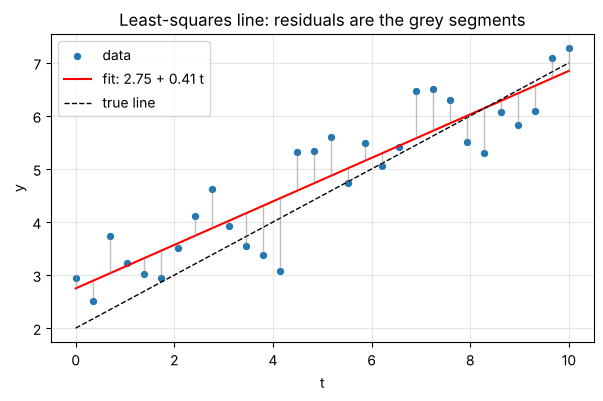

In [8]:
t = np.linspace(0, 10, 30)
y = 2.0 + 0.5 * t + rng.normal(0, 0.8, t.size)          # true line: intercept 2, slope 0.5
A = np.column_stack([np.ones_like(t), t])              # design matrix (30 x 2)

# (a) normal equations, solved (not inverted)
x_normal = np.linalg.solve(A.T @ A, A.T @ y)
# (b) QR: A = Q R  ->  R x = Q^T y  (triangular, well conditioned)
Qm, Rm = np.linalg.qr(A)
x_qr = np.linalg.solve(Rm, Qm.T @ y)
# (c) library call (SVD-based)
x_lstsq, residual_ss, rank, sv = np.linalg.lstsq(A, y, rcond=None)
print("normal eq :", x_normal, "\nQR        :", x_qr, "\nlstsq     :", x_lstsq)
print("rank of A :", rank, "   kappa(A) = %.1f   kappa(A^T A) = %.1f" % (np.linalg.cond(A), np.linalg.cond(A.T @ A)))

# the hat matrix is a symmetric, idempotent projector with trace = number of parameters
H = A @ np.linalg.solve(A.T @ A, A.T)
r = y - H @ y
print("\nH symmetric:", np.allclose(H, H.T), "  H @ H == H:", np.allclose(H @ H, H), "  trace(H) =", np.trace(H).round(6))
print("residual orthogonal to the columns: A^T r =", A.T @ r)
print("leverages (diag of H) range: %.3f .. %.3f, mean %.3f = p/n" % (np.diag(H).min(), np.diag(H).max(), np.diag(H).mean()))

plt.scatter(t, y, s=18, label="data")
plt.plot(t, A @ x_lstsq, "r", label=f"fit: {x_lstsq[0]:.2f} + {x_lstsq[1]:.2f} t")
plt.plot(t, 2.0 + 0.5 * t, "k--", lw=1, label="true line")
plt.vlines(t, A @ x_lstsq, y, color="gray", alpha=0.5, lw=1)
plt.xlabel("t"); plt.ylabel("y"); plt.title("Least-squares line: residuals are the grey segments")
plt.legend(); plt.grid(alpha=0.3); plt.show()

Notice that all three routes give the same coefficients — they solve the same problem — but
$\kappa(A^\top A) = \kappa(A)^2$: forming the Gram matrix squares the condition number, which is
why `lstsq` and QR are preferred for anything wider than a handful of columns. The hat matrix
passes both projection tests, its trace is exactly 2 (the number of parameters), and
$A^\top\mathbf{r} = \mathbf{0}$ to rounding error: the residual vector really is perpendicular to the
column space. "Linear" least squares means linear *in the coefficients*: the same machinery fits a
quadratic once we add a $t^2$ column.

line                : 2 parameters, RSS = 6.237, kappa(A) = 1.2e+01
quadratic           : 3 parameters, RSS = 2.209, kappa(A) = 1.4e+02
degree-6 polynomial : 7 parameters, RSS = 1.700, kappa(A) = 6.4e+06


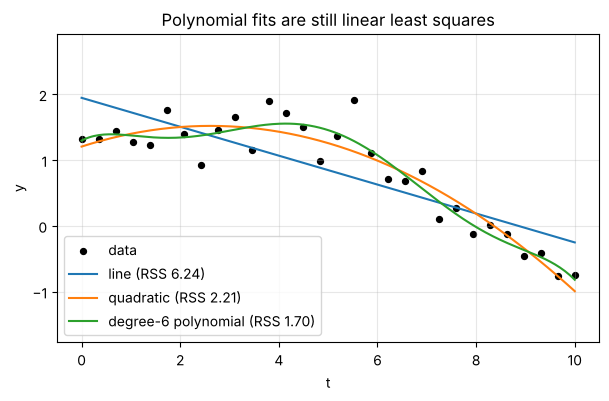

In [9]:
y2 = 1.0 + 0.3 * t - 0.05 * t ** 2 + rng.normal(0, 0.3, t.size)      # curved truth
designs = {"line": np.column_stack([np.ones_like(t), t]),
           "quadratic": np.column_stack([np.ones_like(t), t, t ** 2]),
           "degree-6 polynomial": np.column_stack([t ** k for k in range(7)])}
tt = np.linspace(0, 10, 200)
plt.scatter(t, y2, s=18, color="k", label="data")
for name, A_d in designs.items():
    coef = np.linalg.lstsq(A_d, y2, rcond=None)[0]
    A_tt = np.column_stack([tt ** k for k in range(A_d.shape[1])])
    rss = np.sum((y2 - A_d @ coef) ** 2)
    print(f"{name:20s}: {A_d.shape[1]} parameters, RSS = {rss:.3f}, kappa(A) = {np.linalg.cond(A_d):.1e}")
    plt.plot(tt, A_tt @ coef, label=f"{name} (RSS {rss:.2f})")
plt.ylim(y2.min() - 1, y2.max() + 1)
plt.xlabel("t"); plt.ylabel("y"); plt.title("Polynomial fits are still linear least squares")
plt.legend(); plt.grid(alpha=0.3); plt.show()

Notice that the residual sum of squares can only fall as columns are added — the column space
grows, so the projection gets closer — but the degree-6 fit buys very little over the quadratic
while its design matrix has a condition number millions of times larger. More columns means a
better fit to *these* points, not a better model; Module 13 turns that tension into the
bias–variance trade-off, and Module 03's SVD explains the exploding condition number.

**Try it yourself:** increase the polynomial degree to 12 and look at both `kappa(A)` and the
curve between the data points.

## 8. Change of basis: the same map in better coordinates

If the columns of $P$ form a basis, a vector with standard coordinates $\mathbf{x}$ has new
coordinates $\mathbf{c} = P^{-1}\mathbf{x}$ (so that $\mathbf{x} = P\mathbf{c}$), and a map with matrix $A$
becomes $A' = P^{-1}AP$ in the new coordinates. For $A = \begin{pmatrix}2&1\\1&2\end{pmatrix}$ and the
basis $\mathbf{p}_1 = (1,1)^\top$, $\mathbf{p}_2 = (1,-1)^\top$ the new matrix is diagonal: $A$ just
stretches by 3 along $\mathbf{p}_1$ and by 1 along $\mathbf{p}_2$.

x = [3. 1.]  new coordinates c = [2. 1.]  reconstruct P @ c = [3. 1.]
P^-1 A P =
 [[ 3.  0.]
 [-0.  1.]]
invariants  trace: 4.0 vs 4.0   det: 3.0 vs 3.0


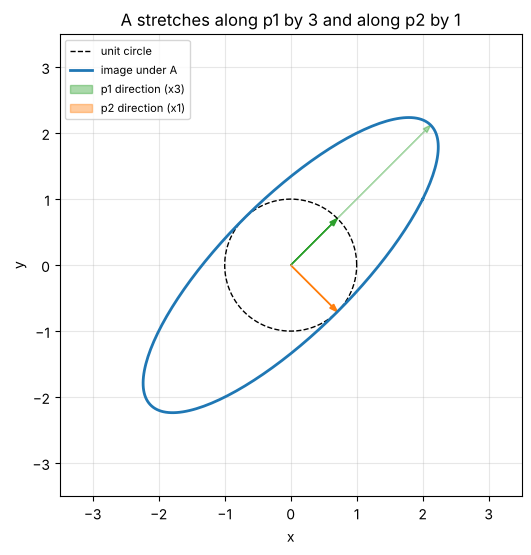

In [10]:
A = np.array([[2., 1.], [1., 2.]])
P = np.array([[1., 1.], [1., -1.]])                  # columns = new basis vectors
x = np.array([3., 1.])
c = np.linalg.solve(P, x)                            # coordinates of x in the new basis
print("x =", x, " new coordinates c =", c, " reconstruct P @ c =", P @ c)
A_new = np.linalg.solve(P, A @ P)                    # P^{-1} A P without forming the inverse
print("P^-1 A P =\n", A_new)
print("invariants  trace: %.1f vs %.1f   det: %.1f vs %.1f" % (np.trace(A), np.trace(A_new), np.linalg.det(A), np.linalg.det(A_new)))

# picture: the unit circle and its image, with the new basis directions
theta = np.linspace(0, 2 * np.pi, 200)
circle = np.vstack([np.cos(theta), np.sin(theta)])
ellipse = A @ circle
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(circle[0], circle[1], "k--", lw=1, label="unit circle")
ax.plot(ellipse[0], ellipse[1], "tab:blue", lw=2, label="image under A")
for i, (col, lab) in enumerate(zip(["tab:green", "tab:orange"], ["p1 direction (x3)", "p2 direction (x1)"])):
    p = P[:, i] / np.linalg.norm(P[:, i])
    ax.arrow(0, 0, *p, head_width=0.08, color=col, length_includes_head=True)
    ax.arrow(0, 0, *(A @ p), head_width=0.08, color=col, alpha=0.4, length_includes_head=True, label=lab)
ax.set_aspect("equal"); ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_title("A stretches along p1 by 3 and along p2 by 1")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()

Notice that the circle becomes an ellipse whose axes are exactly the new basis directions: along
$\mathbf{p}_1$ the arrow triples, along $\mathbf{p}_2$ it is unchanged, and $P^{-1}AP$ records nothing but
those two numbers. Trace and determinant are the same in both coordinate systems — they belong
to the map, not to the matrix. Finding the basis that makes $A$ diagonal is the eigenvalue
problem, and doing it for a covariance matrix is PCA (Module 03).

## 9. Matrices as graphs and Markov chains

An adjacency matrix $A$ has $A_{ij} = 1$ when there is an edge $i \to j$, and $(A^k)_{ij}$ counts
walks of length $k$. A row-stochastic transition matrix $P$ propagates a distribution:
$\boldsymbol\pi_{t+1} = \boldsymbol\pi_t P$. For a well-behaved chain $\boldsymbol\pi_t$ converges to the
stationary distribution $\boldsymbol\pi$ with $\boldsymbol\pi P = \boldsymbol\pi$, whatever the start.

walks of length 2 (A^2):
 [[3 1 2 1]
 [1 2 1 2]
 [2 1 3 1]
 [1 2 1 2]]
walks of length 3 from node 0 to node 3: 5

rows sum to 1: [1. 1. 1.]
pi after 25 steps : [0.5  0.25 0.25]
row of P^200      : [0.5  0.25 0.25]
eigenvector method: [0.5  0.25 0.25]    check pi P = pi: True
eigenvalues of P  : [1.     0.6732 0.3268]  (second one sets the convergence rate)


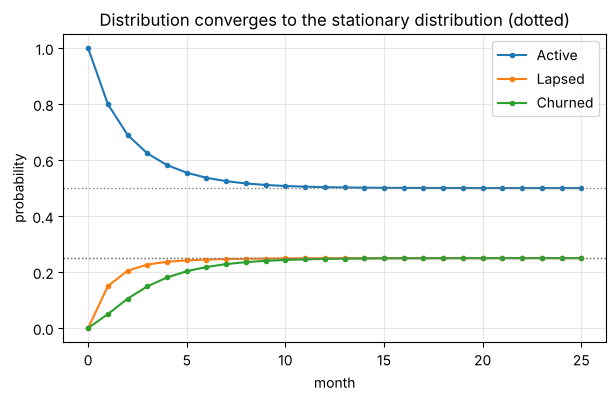

In [11]:
# path counting on a small undirected graph: 0-1, 1-2, 2-3, 3-0, 0-2
Adj = np.array([[0, 1, 1, 1],
                [1, 0, 1, 0],
                [1, 1, 0, 1],
                [1, 0, 1, 0]])
print("walks of length 2 (A^2):\n", Adj @ Adj)
print("walks of length 3 from node 0 to node 3:", np.linalg.matrix_power(Adj, 3)[0, 3])

# a three-state customer chain: Active, Lapsed, Churned-but-returning
Pm = np.array([[0.80, 0.15, 0.05],
               [0.30, 0.50, 0.20],
               [0.10, 0.20, 0.70]])
print("\nrows sum to 1:", Pm.sum(axis=1))
pi = np.array([1., 0., 0.])                           # everyone starts Active
history = [pi]
for step in range(25):
    pi = pi @ Pm
    history.append(pi)
history = np.array(history)

# stationary distribution two ways: a large power, and the eigenvector of P^T for eigenvalue 1
pi_power = np.linalg.matrix_power(Pm, 200)[0]
evals, evecs = np.linalg.eig(Pm.T)
v = np.real(evecs[:, np.argmin(np.abs(evals - 1))]); pi_eig = v / v.sum()
print("pi after 25 steps :", history[-1])
print("row of P^200      :", pi_power)
print("eigenvector method:", pi_eig, "   check pi P = pi:", np.allclose(pi_eig @ Pm, pi_eig))
print("eigenvalues of P  :", np.sort(np.abs(evals))[::-1], " (second one sets the convergence rate)")

for j, lab in enumerate(["Active", "Lapsed", "Churned"]):
    plt.plot(history[:, j], "o-", ms=3, label=lab)
    plt.axhline(pi_eig[j], color="gray", ls=":", lw=1)
plt.xlabel("month"); plt.ylabel("probability"); plt.title("Distribution converges to the stationary distribution (dotted)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

Notice that after about 15 steps the three curves have flattened onto the dotted stationary
values, and that the $200$-th power of $P$ has that same vector as its row — every starting state
leads to the same long-run mix. The gap closes geometrically at the rate of the second-largest
eigenvalue modulus, which is the quantity PageRank and MCMC practitioners care about (Modules 03
and 18). The $A^2$ entries are plain path counts: matrix multiplication is doing combinatorics.

## Summary

* $A\mathbf{x}$ is simultaneously a set of dot products (rows), a combination of columns, a linear
  function and a system of equations; the column picture tells you what outputs are reachable.
* `A @ B` composes maps right-to-left, is not commutative, costs $O(n^3)$, and collapses stacked
  linear layers into one.
* Rotation, scaling, shear, reflection and projection are $2\times2$ matrices; the determinant is the
  signed area factor, and $\det = 0$ means a dimension was destroyed.
* Orthogonal matrices preserve lengths; Gram matrices $A^\top A$ are symmetric PSD; triangular
  systems solve in $O(n^2)$.
* Rank counts independent columns; duplicated or one-hot-trapped features give a non-trivial null
  space and unidentifiable coefficients.
* Use `np.linalg.solve`, never `inv(A) @ b`; the condition number bounds how many digits survive.
* Least squares = projection onto the column space; the normal equations, QR and `lstsq` agree,
  but QR/SVD avoid squaring $\kappa$; the hat matrix is a symmetric idempotent projector.
* $P^{-1}AP$ is the same map in new coordinates — diagonal when $P$ holds the eigenvectors.
* Powers of adjacency matrices count walks; powers of transition matrices converge to the
  stationary distribution.

**Next:** open `exercises.ipynb` and work through the twelve exercises; `solutions.ipynb` has
reference implementations and explanations. Then continue with
[Module 03 — Eigenvalues, SVD and PCA](../03-eigenvalues-svd-and-pca/README.md).